In [1]:

import pandas as pd
import numpy as np

# Assignment settings
RANDOM_SEED = 800
TEST_SIZE = 0.30

# Load the assigned COMPAS dataset
url = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"

df = pd.read_csv(url)

# Display dataset information
print("DATASET LOADED SUCCESSFULLY")
print("-" * 50)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nFIRST 5 ROWS:")
display(df.head())

print("\nMISSING VALUES:")
display(df.isnull().sum().sort_values(ascending=False).head(20))

print("\nPOSSIBLE RECIDIVISM TARGET COLUMNS:")
print([col for col in df.columns if "recid" in col.lower()])


DATASET LOADED SUCCESSFULLY
--------------------------------------------------
Number of rows: 7214
Number of columns: 53

COLUMN NAMES:
['id', 'name', 'first', 'last', 'compas_screening_date', 'sex', 'dob', 'age', 'age_cat', 'race', 'juv_fel_count', 'decile_score', 'juv_misd_count', 'juv_other_count', 'priors_count', 'days_b_screening_arrest', 'c_jail_in', 'c_jail_out', 'c_case_number', 'c_offense_date', 'c_arrest_date', 'c_days_from_compas', 'c_charge_degree', 'c_charge_desc', 'is_recid', 'r_case_number', 'r_charge_degree', 'r_days_from_arrest', 'r_offense_date', 'r_charge_desc', 'r_jail_in', 'r_jail_out', 'violent_recid', 'is_violent_recid', 'vr_case_number', 'vr_charge_degree', 'vr_offense_date', 'vr_charge_desc', 'type_of_assessment', 'decile_score.1', 'score_text', 'screening_date', 'v_type_of_assessment', 'v_decile_score', 'v_score_text', 'v_screening_date', 'in_custody', 'out_custody', 'priors_count.1', 'start', 'end', 'event', 'two_year_recid']

FIRST 5 ROWS:


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0



MISSING VALUES:


violent_recid              7214
vr_charge_degree           6395
vr_case_number             6395
vr_offense_date            6395
vr_charge_desc             6395
c_arrest_date              6077
r_jail_out                 4898
r_jail_in                  4898
r_days_from_arrest         4898
r_charge_desc              3801
r_offense_date             3743
r_case_number              3743
r_charge_degree            3743
c_offense_date             1159
c_jail_out                  307
days_b_screening_arrest     307
c_jail_in                   307
out_custody                 236
in_custody                  236
c_charge_desc                29
dtype: int64


POSSIBLE RECIDIVISM TARGET COLUMNS:
['is_recid', 'violent_recid', 'is_violent_recid', 'two_year_recid']


In [2]:

# Inspect the possible recidivism target columns

for col in ["is_recid", "two_year_recid", "decile_score"]:
    print("\nCOLUMN:", col)
    print("Data type:", df[col].dtype)
    print("Unique values:", sorted(df[col].dropna().unique()))
    print("Missing values:", df[col].isna().sum())
    print("Value counts:")
    display(df[col].value_counts(dropna=False).sort_index())

# Check whether the two recidivism columns agree
comparison = pd.crosstab(
    df["is_recid"],
    df["two_year_recid"],
    dropna=False
)

print("\nIS_RECID vs TWO_YEAR_RECID:")
display(comparison)



COLUMN: is_recid
Data type: int64
Unique values: [np.int64(0), np.int64(1)]
Missing values: 0
Value counts:


is_recid
0    3743
1    3471
Name: count, dtype: int64


COLUMN: two_year_recid
Data type: int64
Unique values: [np.int64(0), np.int64(1)]
Missing values: 0
Value counts:


two_year_recid
0    3963
1    3251
Name: count, dtype: int64


COLUMN: decile_score
Data type: int64
Unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Missing values: 0
Value counts:


decile_score
1     1440
2      941
3      747
4      769
5      681
6      641
7      592
8      512
9      508
10     383
Name: count, dtype: int64


IS_RECID vs TWO_YEAR_RECID:


two_year_recid,0,1
is_recid,,
0,3743,0
1,220,3251


In [3]:

print("Comparison of recidivism columns:")
display(pd.crosstab(
    df["is_recid"],
    df["two_year_recid"],
    rownames=["is_recid"],
    colnames=["two_year_recid"],
    margins=True
))


Comparison of recidivism columns:


two_year_recid,0,1,All
is_recid,,,
0,3743,0,3743
1,220,3251,3471
All,3963,3251,7214


In [4]:

%pip install pandas numpy scikit-learn statsmodels matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


In [4]:

from sklearn.model_selection import train_test_split

# Assignment targets
TARGET_LINEAR = "decile_score"
TARGET_BINARY = "two_year_recid"

# Selected predictors
features = [
    "age",
    "sex",
    "race",
    "priors_count",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count",
    "c_charge_degree"
]

# Keep only required columns
data = df[features + [TARGET_LINEAR, TARGET_BINARY]].copy()

# Remove rows with missing values in selected columns
data = data.dropna().reset_index(drop=True)

# Separate predictors and targets
X = data[features]
y_linear = data[TARGET_LINEAR]
y_binary = data[TARGET_BINARY]

# Same 70/30 split for both models
X_train, X_test, ylin_train, ylin_test, ybin_train, ybin_test = train_test_split(
    X,
    y_linear,
    y_binary,
    test_size=0.30,
    random_state=800
)

print("PREPROCESSING COMPLETE")
print("Rows after cleaning:", len(data))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Random seed: 800")
print("Training percentage:", round(len(X_train)/len(data)*100, 2))
print("Testing percentage:", round(len(X_test)/len(data)*100, 2))
print("\nMissing values remaining:")
print(data.isnull().sum())


NameError: name 'df' is not defined

In [2]:
print("Jupyter is working!")
print("Python is ready.")

Jupyter is working!
Python is ready.


In [5]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Load dataset FIRST
url = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
df = pd.read_csv(url)

print("Dataset loaded:", df.shape)

# Define targets
TARGET_LINEAR = "decile_score"
TARGET_BINARY = "two_year_recid"

# Select predictors
features = [
    "age", "sex", "race", "priors_count",
    "juv_fel_count", "juv_misd_count",
    "juv_other_count", "c_charge_degree"
]

# Prepare data
data = df[features + [TARGET_LINEAR, TARGET_BINARY]].copy()
data = data.dropna().reset_index(drop=True)

X = data[features]
y_linear = data[TARGET_LINEAR]
y_binary = data[TARGET_BINARY]

# Split data using seed 800
X_train, X_test, ylin_train, ylin_test, ybin_train, ybin_test = train_test_split(
    X, y_linear, y_binary,
    test_size=0.30,
    random_state=800
)

print("\nPREPROCESSING COMPLETE")
print("Rows after cleaning:", len(data))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Random seed: 800")
print("\nMissing values:")
print(data.isnull().sum())


Dataset loaded: (7214, 53)

PREPROCESSING COMPLETE
Rows after cleaning: 7214
Training rows: 5049
Testing rows: 2165
Random seed: 800

Missing values:
age                0
sex                0
race               0
priors_count       0
juv_fel_count      0
juv_misd_count     0
juv_other_count    0
c_charge_degree    0
decile_score       0
two_year_recid     0
dtype: int64


In [6]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numeric and categorical predictors
numeric_features = [
    "age",
    "priors_count",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count"
]

categorical_features = [
    "sex",
    "race",
    "c_charge_degree"
]

# Build preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit only on training data; transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("ENCODING AND SCALING COMPLETE")
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("Numeric features scaled:", numeric_features)
print("Categorical features encoded:", categorical_features)
print("Missing values in processed training data:",
      np.isnan(X_train_processed).sum())


ENCODING AND SCALING COMPLETE
Training data shape: (5049, 15)
Testing data shape: (2165, 15)
Numeric features scaled: ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count']
Categorical features encoded: ['sex', 'race', 'c_charge_degree']
Missing values in processed training data: 0


In [7]:

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    mean_squared_error,
    r2_score,
    classification_report
)

# Model A: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train_processed, ylin_train)

# Predict decile scores
linear_predictions = linear_model.predict(X_test_processed)

# Model B: Logistic Regression
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=800
)

logistic_model.fit(X_train_processed, ybin_train)

# Predict recidivism probabilities
logistic_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

logistic_predictions = (logistic_probabilities >= 0.5).astype(int)

# Evaluate Model A
print("MODEL A: LINEAR REGRESSION")
print("R-squared:", round(r2_score(ylin_test, linear_predictions), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(
    ylin_test, linear_predictions
)), 4))
print("Median predicted decile score:",
      round(float(np.median(linear_predictions)), 4))

# Evaluate Model B
print("\nMODEL B: LOGISTIC REGRESSION")
print("Accuracy:", round(accuracy_score(
    ybin_test, logistic_predictions
), 4))
print("\nClassification report:")
print(classification_report(
    ybin_test,
    logistic_predictions,
    zero_division=0
))


MODEL A: LINEAR REGRESSION
R-squared: 0.429
RMSE: 2.1755
Median predicted decile score: 4.553

MODEL B: LOGISTIC REGRESSION
Accuracy: 0.685

Classification report:
              precision    recall  f1-score   support

           0       0.70      0.77      0.73      1210
           1       0.66      0.58      0.62       955

    accuracy                           0.68      2165
   macro avg       0.68      0.67      0.68      2165
weighted avg       0.68      0.68      0.68      2165



In [8]:

from sklearn.metrics import confusion_matrix

# Linear regression: classify using median predicted score
linear_threshold = np.median(linear_predictions)
linear_high_risk = (linear_predictions >= linear_threshold).astype(int)

# Logistic regression: classify using probability threshold 0.5
logistic_high_risk = (logistic_probabilities >= 0.5).astype(int)

# Compare agreement between the two models
agreement_matrix = confusion_matrix(
    linear_high_risk,
    logistic_high_risk,
    labels=[0, 1]
)

mismatch_count = np.sum(linear_high_risk != logistic_high_risk)
mismatch_percentage = mismatch_count / len(linear_high_risk) * 100

print("PART 1: MODEL AGREEMENT")
print("\nConfusion matrix:")
print(agreement_matrix)

print("\nRows = Linear Regression")
print("Columns = Logistic Regression")
print("Order: Low risk (0), High risk (1)")

print("\nTotal test cases:", len(linear_high_risk))
print("Mismatched cases:", mismatch_count)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")
print("Agreement percentage:", round(100 - mismatch_percentage, 2), "%")
print("Linear regression threshold:", round(linear_threshold, 4))
print("Logistic regression threshold: 0.5")


PART 1: MODEL AGREEMENT

Confusion matrix:
[[1055   25]
 [ 277  808]]

Rows = Linear Regression
Columns = Logistic Regression
Order: Low risk (0), High risk (1)

Total test cases: 2165
Mismatched cases: 302
Mismatch percentage: 13.95 %
Agreement percentage: 86.05 %
Linear regression threshold: 4.553
Logistic regression threshold: 0.5


In [9]:

import statsmodels.formula.api as smf
import pandas as pd

# Use the same cleaned dataset
# Gender is used to define the two subgroups.
# priors_count is the key predictor we will compare.

formula = (
    "two_year_recid ~ age + priors_count + "
    "juv_fel_count + juv_misd_count + juv_other_count + "
    "C(race) + C(c_charge_degree)"
)

# Fit full dataset model
model_full = smf.logit(formula, data=data).fit(disp=False, maxiter=200)

# Split into male and female subgroups
male_data = data[data["sex"] == "Male"].copy()
female_data = data[data["sex"] == "Female"].copy()

model_male = smf.logit(
    formula, data=male_data
).fit(disp=False, maxiter=200)

model_female = smf.logit(
    formula, data=female_data
).fit(disp=False, maxiter=200)

# Extract coefficient and confidence interval for priors_count
def get_prior_result(model, group_name):
    coef = model.params["priors_count"]
    ci_low, ci_high = model.conf_int().loc["priors_count"]

    return {
        "Group": group_name,
        "Coefficient": coef,
        "CI lower": ci_low,
        "CI upper": ci_high,
        "P-value": model.pvalues["priors_count"]
    }

results = pd.DataFrame([
    get_prior_result(model_full, "Full dataset"),
    get_prior_result(model_male, "Male"),
    get_prior_result(model_female, "Female")
])

print("PART 2.1: PRIORS COUNT EFFECT BY GENDER")
display(results.round(4))

print("Number of male records:", len(male_data))
print("Number of female records:", len(female_data))


PART 2.1: PRIORS COUNT EFFECT BY GENDER


,Group,Coefficient,CI lower,CI upper,P-value
0,Full dataset,0.1479,0.1340,0.1619,0.0
1,Male,0.1369,0.1221,0.1516,0.0
2,Female,0.2082,0.1648,0.2517,0.0


Number of male records: 5819
Number of female records: 1395


In [10]:

# Formal interaction test: does the priors_count effect differ by sex?

interaction_model = smf.logit(
    "two_year_recid ~ priors_count * C(sex) + age + "
    "juv_fel_count + juv_misd_count + juv_other_count + "
    "C(race) + C(c_charge_degree)",
    data=data
).fit(disp=False, maxiter=200)

print("GENDER INTERACTION TEST")
print(interaction_model.summary())

print("\nInteraction coefficient:")
print(interaction_model.params.filter(like="priors_count:C(sex)"))

print("\nInteraction p-value:")
print(interaction_model.pvalues.filter(like="priors_count:C(sex)"))


GENDER INTERACTION TEST
                           Logit Regression Results                           
Dep. Variable:         two_year_recid   No. Observations:                 7214
Model:                          Logit   Df Residuals:                     7200
Method:                           MLE   Df Model:                           13
Date:                Wed, 25 Nov 2026   Pseudo R-squ.:                  0.1117
Time:                        00:15:49   Log-Likelihood:                -4410.6
converged:                       True   LL-Null:                       -4965.2
Covariance Type:            nonrobust   LLR p-value:                6.460e-229
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                       0.5101      0.111      4.611      0.000       0.293       0.727
C(sex)[T.Male]                  0.4759      0.084      5

In [11]:

# Full model
full_formula = (
    "two_year_recid ~ age + priors_count + juv_fel_count + "
    "juv_misd_count + juv_other_count + C(sex) + C(race) + "
    "C(c_charge_degree)"
)

# Reduced model: deliberately omit priors_count
reduced_formula = (
    "two_year_recid ~ age + juv_fel_count + "
    "juv_misd_count + juv_other_count + C(sex) + C(race) + "
    "C(c_charge_degree)"
)

full_ovb = smf.logit(full_formula, data=data).fit(disp=False)
reduced_ovb = smf.logit(reduced_formula, data=data).fit(disp=False)

# Compare at least four predictors
predictors_to_compare = [
    "age",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count",
    "C(sex)[T.Male]"
]

comparison = []

for predictor in predictors_to_compare:
    before = full_ovb.params[predictor]
    after = reduced_ovb.params[predictor]

    pct_change = (
        abs((after - before) / before) * 100
        if before != 0 else np.nan
    )

    comparison.append({
        "Predictor": predictor,
        "Full coefficient": before,
        "Reduced coefficient": after,
        "Absolute percentage change": pct_change
    })

ovb_table = pd.DataFrame(comparison)

print("PART 2.2: OMITTED-VARIABLE BIAS")
print("Variable deliberately omitted: priors_count")
display(ovb_table.round(4))

largest = ovb_table.loc[
    ovb_table["Absolute percentage change"].idxmax()
]
print("\nLargest coefficient change:")
print(largest)


PART 2.2: OMITTED-VARIABLE BIAS
Variable deliberately omitted: priors_count


,Predictor,Full coefficient,Reduced coefficient,Absolute percentage change
0,age,-0.0441,-0.0272,38.2735
1,juv_fel_count,0.1626,0.4342,167.0513
2,juv_misd_count,0.0209,0.3437,1544.9396
3,juv_other_count,0.1839,0.2815,53.0571
4,C(sex)[T.Male],0.2967,0.4142,39.6253



Largest coefficient change:
Predictor                     juv_misd_count
Full coefficient                    0.020895
Reduced coefficient                 0.343713
Absolute percentage change       1544.939642
Name: 2, dtype: object


In [12]:

# Build a test-set results table
test_results = X_test.reset_index(drop=True).copy()
test_results["actual"] = np.array(ybin_test)
test_results["probability"] = logistic_probabilities

# Identify high-confidence incorrect predictions
false_positives = test_results[
    (test_results["probability"] >= 0.75) &
    (test_results["actual"] == 0)
]

false_negatives = test_results[
    (test_results["probability"] <= 0.25) &
    (test_results["actual"] == 1)
]

adversarial_all = pd.concat(
    [false_positives, false_negatives]
).sort_index()

# Randomly select up to 50 cases
adversarial = adversarial_all.sample(
    n=min(50, len(adversarial_all)),
    random_state=800
)

# Calculate overall count and percentage
count_wrong = len(adversarial_all)
percentage_wrong = count_wrong / len(test_results) * 100

print("PART 2.3: ADVERSARIAL SUBSET")
print("High-confidence wrong predictions:", count_wrong)
print("Percentage of test set:", round(percentage_wrong, 2), "%")
print("Rows selected for analysis:", len(adversarial))
print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

# Compare characteristics with the full test set
comparison = pd.DataFrame({
    "Characteristic": [
        "Average age",
        "Median age",
        "Average prior offences",
        "Median prior offences",
        "Percentage with priors_count >= 5",
        "Percentage male",
        "Percentage African-American"
    ],
    "Full test set": [
        test_results["age"].mean(),
        test_results["age"].median(),
        test_results["priors_count"].mean(),
        test_results["priors_count"].median(),
        (test_results["priors_count"] >= 5).mean() * 100,
        (test_results["sex"] == "Male").mean() * 100,
        (test_results["race"] == "African-American").mean() * 100
    ],
    "Adversarial subset": [
        adversarial["age"].mean(),
        adversarial["age"].median(),
        adversarial["priors_count"].mean(),
        adversarial["priors_count"].median(),
        (adversarial["priors_count"] >= 5).mean() * 100,
        (adversarial["sex"] == "Male").mean() * 100,
        (adversarial["race"] == "African-American").mean() * 100
    ]
})

display(comparison.round(2))

print("\nFirst 10 adversarial cases:")
display(adversarial.head(10))


PART 2.3: ADVERSARIAL SUBSET
High-confidence wrong predictions: 94
Percentage of test set: 4.34 %
Rows selected for analysis: 50
False positives: 38
False negatives: 56


,Characteristic,Full test set,Adversarial subset
0,Average age,34.61,47.12
1,Median age,31.00,50.00
2,Average prior offences,3.58,6.84
3,Median prior offences,2.00,2.00
4,Percentage with priors_count >= 5,26.00,38.00
5,Percentage male,80.74,78.00
6,Percentage African-American,51.18,48.00



First 10 adversarial cases:


,age,sex,race,priors_count,juv_fel_count,juv_misd_count,juv_other_count,c_charge_degree,actual,probability
603,50,Male,Caucasian,0,0,0,0,F,1,0.219964
1858,27,Male,African-American,10,0,0,0,F,0,0.786185
1879,54,Male,Caucasian,1,0,0,0,F,1,0.216111
495,61,Male,African-American,25,0,0,0,F,0,0.891298
670,55,Male,Caucasian,0,0,0,0,M,1,0.164462
517,47,Female,Caucasian,0,0,0,0,M,1,0.168319
1175,50,Female,Hispanic,1,0,0,0,F,1,0.161657
1107,57,Male,Caucasian,0,0,0,0,M,1,0.152754
221,41,Male,Asian,2,0,0,0,F,1,0.237151
2088,46,Female,African-American,1,0,0,0,F,1,0.225947


In [13]:

import matplotlib.pyplot as plt

# Build fairness test data
fair_data = X_test.reset_index(drop=True).copy()
fair_data["actual"] = np.array(ybin_test)
fair_data["probability"] = logistic_probabilities

# Compare African-American and Caucasian groups only
group_A = fair_data[fair_data["race"] == "African-American"].copy()
group_B = fair_data[fair_data["race"] == "Caucasian"].copy()

def safe_ratio(a, b):
    if pd.isna(a) or pd.isna(b) or b == 0:
        return np.nan
    return a / b

thresholds = np.round(np.arange(0.05, 1.00, 0.10), 2)
fairness_results = []

for t in thresholds:
    A_pred = (group_A["probability"] >= t).astype(int)
    B_pred = (group_B["probability"] >= t).astype(int)

    # Demographic parity
    dp_A = A_pred.mean()
    dp_B = B_pred.mean()
    dp = safe_ratio(dp_A, dp_B)

    # True positive and false positive rates
    tpr_A = (
        A_pred[group_A["actual"] == 1].mean()
    )
    tpr_B = (
        B_pred[group_B["actual"] == 1].mean()
    )

    fpr_A = (
        A_pred[group_A["actual"] == 0].mean()
    )
    fpr_B = (
        B_pred[group_B["actual"] == 0].mean()
    )

    eo = min(
        safe_ratio(tpr_A, tpr_B),
        safe_ratio(fpr_A, fpr_B)
    ) if (
        not pd.isna(safe_ratio(tpr_A, tpr_B))
        and not pd.isna(safe_ratio(fpr_A, fpr_B))
    ) else np.nan

    # Predictive parity (precision)
    pp_A = (
        group_A.loc[A_pred == 1, "actual"].mean()
        if A_pred.sum() > 0 else np.nan
    )

    pp_B = (
        group_B.loc[B_pred == 1, "actual"].mean()
        if B_pred.sum() > 0 else np.nan
    )

    pp = safe_ratio(pp_A, pp_B)

    fairness_results.append({
        "Threshold": t,
        "DP": dp,
        "EO": eo,
        "PP": pp,
        "DP Group A": dp_A,
        "DP Group B": dp_B,
        "TPR A": tpr_A,
        "TPR B": tpr_B,
        "FPR A": fpr_A,
        "FPR B": fpr_B,
        "PP A": pp_A,
        "PP B": pp_B
    })

fairness_table = pd.DataFrame(fairness_results)

print("PART 2.4: FAIRNESS METRICS")
display(fairness_table.round(4))

print("\nGroup A size:", len(group_A))
print("Group B size:", len(group_B))


Matplotlib is building the font cache; this may take a moment.


PART 2.4: FAIRNESS METRICS


,Threshold,DP,EO,PP,DP Group A,DP Group B,TPR A,TPR B,FPR A,FPR B,PP A,PP B
0,0.05,1.0000,1.0000,1.3512,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.5108,0.3780
1,0.15,1.0487,1.0220,1.3168,0.9919,0.9458,1.0000,0.9785,0.9834,0.9259,0.5150,0.3911
2,0.25,1.1943,1.0888,1.2319,0.9386,0.7859,0.9717,0.8925,0.9041,0.7211,0.5288,0.4293
3,0.35,1.3930,1.2070,1.1708,0.8475,0.6084,0.9258,0.7670,0.7657,0.5120,0.5580,0.4766
4,0.45,1.6781,1.4369,1.1570,0.6435,0.3835,0.7880,0.5484,0.4926,0.2832,0.6255,0.5406
5,0.55,2.2697,1.7388,1.0351,0.3998,0.1762,0.5671,0.3262,0.2251,0.0850,0.7246,0.7000
6,0.65,2.7864,1.9516,0.9464,0.2265,0.0813,0.3428,0.1756,0.1052,0.0240,0.7729,0.8167
7,0.75,4.1074,3.2041,1.0541,0.1336,0.0325,0.2067,0.0645,0.0572,0.0131,0.7905,0.7500
8,0.85,4.6625,3.4505,1.0000,0.0695,0.0149,0.1113,0.0323,0.0258,0.0044,0.8182,0.8182
9,0.95,3.9964,NaN,0.9167,0.0108,0.0027,0.0194,0.0072,0.0018,0.0000,0.9167,1.0000



Group A size: 1108
Group B size: 738


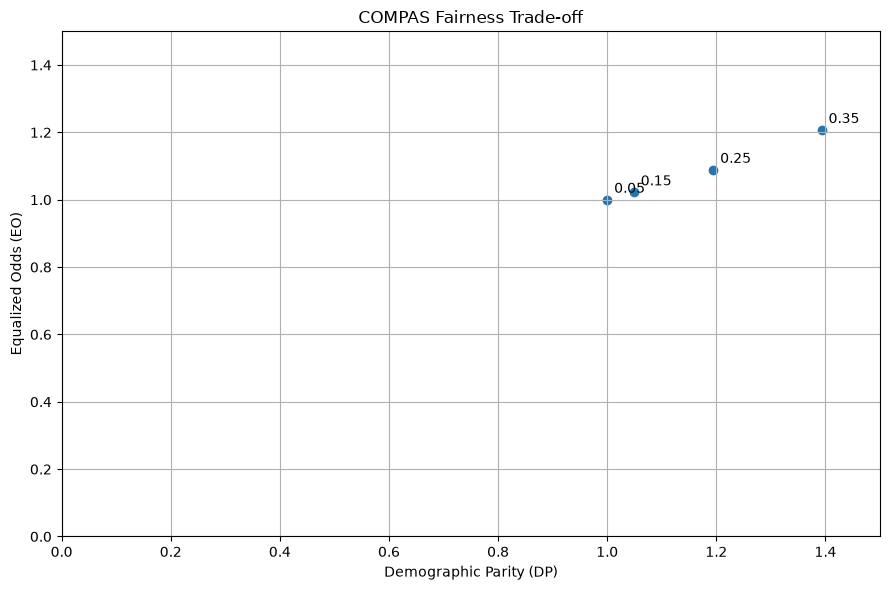

In [16]:

plt.figure(figsize=(9, 6))

plt.scatter(fairness_table["DP"], fairness_table["EO"])

for _, row in fairness_table.iterrows():
    if pd.notna(row["DP"]) and pd.notna(row["EO"]):
        plt.annotate(
            f'{row["Threshold"]:.2f}',
            (row["DP"], row["EO"]),
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity (DP)")
plt.ylabel("Equalized Odds (EO)")
plt.title("COMPAS Fairness Trade-off")
plt.grid(True)
plt.tight_layout()

plt.savefig("COMPAS_fairness_tradeoff.png", dpi=300)
plt.show()


In [15]:

# Compare threshold 0.15 with threshold 0.55
low = fairness_table[fairness_table["Threshold"] == 0.15].iloc[0]
high = fairness_table[fairness_table["Threshold"] == 0.55].iloc[0]

print("TRADE-OFF: THRESHOLD 0.15 TO 0.55")

for metric in ["DP", "EO", "PP"]:
    change = (high[metric] - low[metric]) / abs(low[metric]) * 100
    print(
        metric,
        "at 0.15:", round(low[metric], 4),
        "| at 0.55:", round(high[metric], 4),
        "| percentage change:", round(change, 2), "%"
    )


TRADE-OFF: THRESHOLD 0.15 TO 0.55
DP at 0.15: 1.0487 | at 0.55: 2.2697 | percentage change: 116.43 %
EO at 0.15: 1.022 | at 0.55: 1.7388 | percentage change: 70.14 %
PP at 0.15: 1.3168 | at 0.55: 1.0351 | percentage change: -21.39 %
